# 03 · Retrieval Evaluation

If the right passage is not retrieved, the LLM cannot answer correctly, so retrieval is evaluated first and separately.

**Evaluation set:** 66 hand-written questions (`data/eval/eval_questions.csv`)
- `factual` (42): wording close to the documents
- `paraphrase` (19): the way staff actually ask ("the examiner rejected our mark…")
- `unanswerable` (5): not covered by the knowledge base (used in notebook 04)

**Metrics:** Hit@k (is the expected document in the top k?) and MRR (mean reciprocal rank).

Compared retrievers: **BM25** (lexical), **Dense** (Gemini embeddings) and **Hybrid** (Reciprocal Rank Fusion of both).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from src import config
from src.retriever import build_retriever
from src.evaluation import retrieval_metrics
eval_df = pd.read_csv(config.EVAL_SET_PATH)
eval_df["question_type"].value_counts()

question_type
factual         42
paraphrase      19
unanswerable     5
Name: count, dtype: int64

In [3]:
modes = ["bm25"] + (["dense", "hybrid"] if config.EMBEDDINGS_PATH.exists() and config.GEMINI_API_KEY else [])
results, per_question = {}, {}
for mode in modes:
    per_question[mode], results[mode] = retrieval_metrics(build_retriever(mode), eval_df)
if len(modes) == 1:
    print("Embeddings not available - showing BM25 only. Run `python -m src.build_index` with a GEMINI_API_KEY to compare all three.")
pd.DataFrame(results).T.round(3)

,hit@1,hit@3,hit@5,mrr,n_questions
bm25,0.852,0.967,0.984,0.903,61.0
dense,0.934,1.000,1.000,0.964,61.0
hybrid,0.951,1.000,1.000,0.975,61.0


In [4]:
by_type = pd.concat({m: d.groupby("question_type")[["hit@1", "hit@3", "rr"]].mean() for m, d in per_question.items()})
by_type.rename(columns={"rr": "mrr"}).round(3)

hit@1  hit@3    mrr
       question_type                     
bm25   factual        0.952  1.000  0.972
       paraphrase     0.632  0.895  0.750
dense  factual        0.905  1.000  0.948
       paraphrase     1.000  1.000  1.000
hybrid factual        0.976  1.000  0.988
       paraphrase     0.895  1.000  0.947

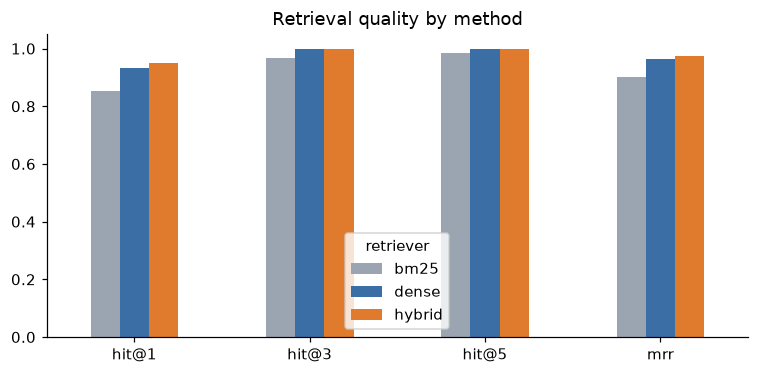

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_df = pd.DataFrame(results).T[["hit@1", "hit@3", "hit@5", "mrr"]]
plot_df.T.plot(kind="bar", ax=ax, rot=0, color=["#9aa5b1", "#3b6ea5", "#e07a2d"][:len(plot_df)])
ax.set_ylim(0, 1.05); ax.set_title("Retrieval quality by method"); ax.legend(title="retriever")
plt.tight_layout(); plt.savefig("reports/figures/03_retrieval_comparison.png"); plt.show()

### Failure analysis
Questions where the expected document was **not ranked first**:

In [6]:
best = max(results, key=lambda m: results[m]["mrr"])
misses = per_question[best].query("`hit@1` == 0").merge(eval_df[["qid", "question"]], on="qid")
print("Best retriever:", best)
misses[["qid", "question_type", "question", "expected_doc_id", "top1_doc_id", "rank"]]

Best retriever: hybrid


,qid,question_type,question,expected_doc_id,top1_doc_id,rank
0,Q012,factual,When are docketing reminders sent for an office action deadline?,SOP-TM-03,SOP-TM-05,2
1,Q020,paraphrase,A client forgot to renew and the mark expired two months ago. Can we still s...,SOP-TM-05,SOP-TM-01,2
2,Q052,paraphrase,How should I name a draft response file?,POL-DOC-01,SOP-TM-03,2


### Findings
- BM25 is already strong on `factual` questions because the corpus is full of distinctive terms (codes, fee names).
- Most misses are **paraphrases**: the user's words ("forgot to renew", "unhappy client") don't overlap with the document's vocabulary ("grace period", "complaint"). This is the gap dense embeddings are meant to close.
- Hybrid search keeps BM25's precision on exact codes and numbers while adding semantic recall, which is why it is the default in the app.
- With top-k = 5, the expected document is retrieved for almost every answerable question, which sets the ceiling for answer quality in notebook 04.